# CU-BEMS Starter EDA — Floor 5 (Jul 2018 – Dec 2019)

**Purpose of this notebook:** 
Conducting preliminary EDA on floor 5 of the building to identify areas of the following: 

1. Descibing dataset
2. Missing data? 
3. Any impossible values due to faulty instances of IOTs 
4. How much does the floor use? Categorised into end-use and zone movements
5. What does a typical day look like? Are there any changes in a week or year?
6. What are some of the indoor conditions (temperature, humidity, light)? 
7. Conclusion + Recomendations

**About the dataset.** CU-BEMS comes from a 7-floor, 11,700 m² office building at Chulalongkorn
University, Bangkok. Every minute it records, for each zone on a floor:

| Channel | Unit | Meaning |
|---|---|---|
| `AC1..ACn` | kW | Power drawn by one air-conditioning unit |
| `Light` | kW | Power drawn by the zone's lighting circuit |
| `Plug` | kW | Power drawn by the zone's socket / plug loads |
| `S1(degC)` | °C | Indoor temperature from sensor 1 |
| `S1(RH%)` | % | Relative humidity from sensor 1 |
| `S1(lux)` | lux | Ambient light from sensor 1 |

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df_floor5_2018 = pd.read_csv('../data/2018Floor5.csv', parse_dates=['Date'])
df_floor5_2019 = pd.read_csv('../data/2019Floor5.csv', parse_dates=['Date'])

print("First 5 rows of Floor 5 2019")
df_floor5_2019.head()

First 5 rows of Floor 5 2019


,Date,z1_AC1(kW),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),...,z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
0,2019-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.13,NaN,NaN,NaN,...,0.39,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
1,2019-01-01 00:01:00,0.0,0.0,0.0,0.0,0.0,0.13,NaN,NaN,NaN,...,0.41,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
2,2019-01-01 00:02:00,0.0,0.0,0.0,0.0,0.0,0.12,NaN,NaN,NaN,...,0.35,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
3,2019-01-01 00:03:00,0.0,0.0,0.0,0.0,0.0,0.12,NaN,NaN,NaN,...,0.34,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN
4,2019-01-01 00:04:00,0.0,0.0,0.0,0.0,0.0,0.12,NaN,NaN,NaN,...,0.35,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN


## Understanding 2018 Floor 5 files

2018 file starts on 1 July 2018

In [34]:
print("First 5 rows of Floor 5 2018")
df_floor5_2018.head()
df_floor5_2018.describe()
df_floor5_2018.info()

First 5 rows of Floor 5 2018
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264960 entries, 0 to 264959
Data columns (total 30 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Date          264960 non-null  datetime64[ns]
 1   z1_AC1(kW)    258039 non-null  float64       
 2   z1_AC2(kW)    258039 non-null  float64       
 3   z1_AC3(kW)    258039 non-null  float64       
 4   z1_AC4(kW)    255970 non-null  float64       
 5   z1_Light(kW)  257619 non-null  float64       
 6   z1_Plug(kW)   258333 non-null  float64       
 7   z1_S1(degC)   102023 non-null  float64       
 8   z1_S1(RH%)    102023 non-null  float64       
 9   z1_S1(lux)    102023 non-null  float64       
 10  z2_AC1(kW)    255980 non-null  float64       
 11  z2_Light(kW)  256798 non-null  float64       
 12  z2_Plug(kW)   256798 non-null  float64       
 13  z2_S1(degC)   100635 non-null  float64       
 14  z2_S1(RH%)    100635 non-null  float64 

## Understanding 2019 Floor 5 files

The 2019 file is a dataset of the whole calendar year. 

In [35]:
print("First 5 rows of Floor 5 2019")
df_floor5_2019.head()
df_floor5_2019.describe()
df_floor5_2019.info()

First 5 rows of Floor 5 2019
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525600 entries, 0 to 525599
Data columns (total 30 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Date          525600 non-null  datetime64[ns]
 1   z1_AC1(kW)    518917 non-null  float64       
 2   z1_AC2(kW)    518917 non-null  float64       
 3   z1_AC3(kW)    518917 non-null  float64       
 4   z1_AC4(kW)    495469 non-null  float64       
 5   z1_Light(kW)  524862 non-null  float64       
 6   z1_Plug(kW)   524986 non-null  float64       
 7   z1_S1(degC)   359015 non-null  float64       
 8   z1_S1(RH%)    359015 non-null  float64       
 9   z1_S1(lux)    359015 non-null  float64       
 10  z2_AC1(kW)    495537 non-null  float64       
 11  z2_Light(kW)  504272 non-null  float64       
 12  z2_Plug(kW)   504272 non-null  float64       
 13  z2_S1(degC)   301827 non-null  float64       
 14  z2_S1(RH%)    301827 non-null  float64 

## Combining 2 CSV files for Floor 5

Merging it for simplier trend analysis

In [36]:
df = pd.concat([df_floor5_2018, df_floor5_2019]).set_index("Date").sort_index()

# To check if both df has been properly concatenated.
display(df.head())
display(df.tail())

,z1_AC1(kW),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),...,z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
Date,,,,,,,,,,,,,,,,,,,,,
2018-07-01 00:00:00,0.0,0.0,0.0,0.0,0.34,0.17,27.54,68.29,3.0,0.0,...,0.24,27.55,70.36,0.0,0.0,0.0,0.01,28.16,68.51,1.0
2018-07-01 00:01:00,0.0,0.0,0.0,0.0,0.33,0.17,27.54,68.30,3.0,0.0,...,0.24,27.55,70.37,0.0,0.0,0.0,0.01,28.17,68.50,1.0
2018-07-01 00:02:00,0.0,0.0,0.0,0.0,0.28,0.16,27.54,68.30,3.0,0.0,...,0.22,27.55,70.37,0.0,0.0,0.0,0.01,28.16,68.48,1.0
2018-07-01 00:03:00,0.0,0.0,0.0,0.0,0.33,0.17,27.54,68.30,3.0,0.0,...,0.23,27.55,70.38,0.0,0.0,0.0,0.01,28.16,68.48,1.0
2018-07-01 00:04:00,0.0,0.0,0.0,0.0,0.34,0.12,27.54,68.30,3.0,0.0,...,0.23,27.55,70.38,0.0,0.0,0.0,0.01,28.16,68.46,1.0


,z1_AC1(kW),z1_AC2(kW),z1_AC3(kW),z1_AC4(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),...,z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
Date,,,,,,,,,,,,,,,,,,,,,
2019-12-31 23:55:00,0.0,0.0,0.0,0.0,0.0,0.21,26.45,62.6,0.0,0.0,...,0.30,26.3,66.57,0.0,0.0,0.0,0.0,27.66,65.20,1.0
2019-12-31 23:56:00,0.0,0.0,0.0,0.0,0.0,0.20,26.45,62.5,0.0,0.0,...,0.30,26.3,66.54,0.0,0.0,0.0,0.0,27.65,65.23,1.0
2019-12-31 23:57:00,0.0,0.0,0.0,0.0,0.0,0.20,26.45,62.6,0.0,0.0,...,0.35,26.3,66.57,0.0,0.0,0.0,0.0,27.65,65.22,1.0
2019-12-31 23:58:00,0.0,0.0,0.0,0.0,0.0,0.19,26.44,62.9,0.0,0.0,...,0.44,26.3,66.53,0.0,0.0,0.0,0.0,27.66,65.19,1.0
2019-12-31 23:59:00,0.0,0.0,0.0,0.0,0.0,0.19,26.45,62.6,0.0,0.0,...,0.43,26.3,66.55,0.0,0.0,0.0,0.0,27.66,65.22,1.0


## 3. What does each column mean?

Column names follow the pattern `z<zone>_<channel>(<unit>)`. 

In [37]:
measurements = (df.columns.to_series(name="column").reset_index(drop=True)
         .str.extract(r"^(?P<zone>z\d+)_(?P<channel>[A-Za-z]+)\d*\((?P<unit>[^)]+)\)$"))

measurements.insert(0, "column", df.columns)
measurements["kind"] = measurements["channel"].where(measurements["channel"] != "S", measurements["unit"])
measurements

# S -> sensors
# Measurements -> What quantity is this column actually measuring? 
# Observation: The data set contains a mixture of IOT and appliances recording. 

,column,zone,channel,unit,kind
0,z1_AC1(kW),z1,AC,kW,AC
1,z1_AC2(kW),z1,AC,kW,AC
2,z1_AC3(kW),z1,AC,kW,AC
3,z1_AC4(kW),z1,AC,kW,AC
4,z1_Light(kW),z1,Light,kW,Light
5,z1_Plug(kW),z1,Plug,kW,Plug
6,z1_S1(degC),z1,S,degC,degC
7,z1_S1(RH%),z1,S,RH%,RH%
8,z1_S1(lux),z1,S,lux,lux
9,z2_AC1(kW),z2,AC,kW,AC


In [38]:
# One line per zone(5): What each zone is capable of measuring? 

measurements.groupby("zone")["kind"].apply(lambda s: ", ".join(sorted(s))).to_frame("channels available")

,channels available
zone,
z1,"AC, AC, AC, AC, Light, Plug, RH%, degC, lux"
z2,"AC, Light, Plug, RH%, degC, lux"
z3,"Light, Plug"
z4,"AC, Light, Plug, RH%, degC, lux"
z5,"AC, Light, Plug, RH%, degC, lux"


**Takeaways**

- Zone 1 has **four** AC units, every other zone has one.
- **Zone 3 has no AC and no sensor** – only lighting and plug loads. Any comfort or AC analysis excludes z3.
- Four zones (z1, z2, z4, z5) have one indoor sensor each reporting temperature, humidity and light.

In [39]:
AC_COLS = measurements.loc[measurements.kind == 'AC', 'column'].tolist()
LIGHT_COLS = measurements.loc[measurements.kind == 'Light', 'column'].tolist()
PLUG_COLS = measurements.loc[measurements.kind == 'Plug', 'column'].tolist()
TEMP_COLS = measurements.loc[measurements.kind == 'degC', 'column'].tolist()
RELATIVE_HUMIDITY_COLS = measurements.loc[measurements.kind == 'RH%', 'column'].tolist()
ILLUMINANCE = measurements.loc[measurements.kind == "lux", "column"].tolist()
POWER_COLS = AC_COLS + LIGHT_COLS + PLUG_COLS
IEQ = TEMP_COLS + RELATIVE_HUMIDITY_COLS + ILLUMINANCE # IEQ = Indoor Environmental Quality 

print("AC   :", AC_COLS)
print("Light:", LIGHT_COLS)
print("Plug :", PLUG_COLS)
print("Temp :", TEMP_COLS)

AC   : ['z1_AC1(kW)', 'z1_AC2(kW)', 'z1_AC3(kW)', 'z1_AC4(kW)', 'z2_AC1(kW)', 'z4_AC1(kW)', 'z5_AC1(kW)']
Light: ['z1_Light(kW)', 'z2_Light(kW)', 'z3_Light(kW)', 'z4_Light(kW)', 'z5_Light(kW)']
Plug : ['z1_Plug(kW)', 'z2_Plug(kW)', 'z3_Plug(kW)', 'z4_Plug(kW)', 'z5_Plug(kW)']
Temp : ['z1_S1(degC)', 'z2_S1(degC)', 'z4_S1(degC)', 'z5_S1(degC)']


## Time axis checks

There should be one row per minute for a one minute data. Check for: 

1. Duplicated
2. Gaps?
3. Expected number of row

In [41]:
print("Duplicate timestamps :", df.index.duplicated().sum())
expected = int((df.index.max() - df.index.min()) / pd.Timedelta(minutes=1)) + 1
print(f"Rows present | expected: {len(df):,} | {expected:,}")


Duplicate timestamps : 0
Rows present | expected: 790,560 | 790,560


## Where is data missing

Basis of comparision

- Share of empty cells per column 
- When they are empty (month)


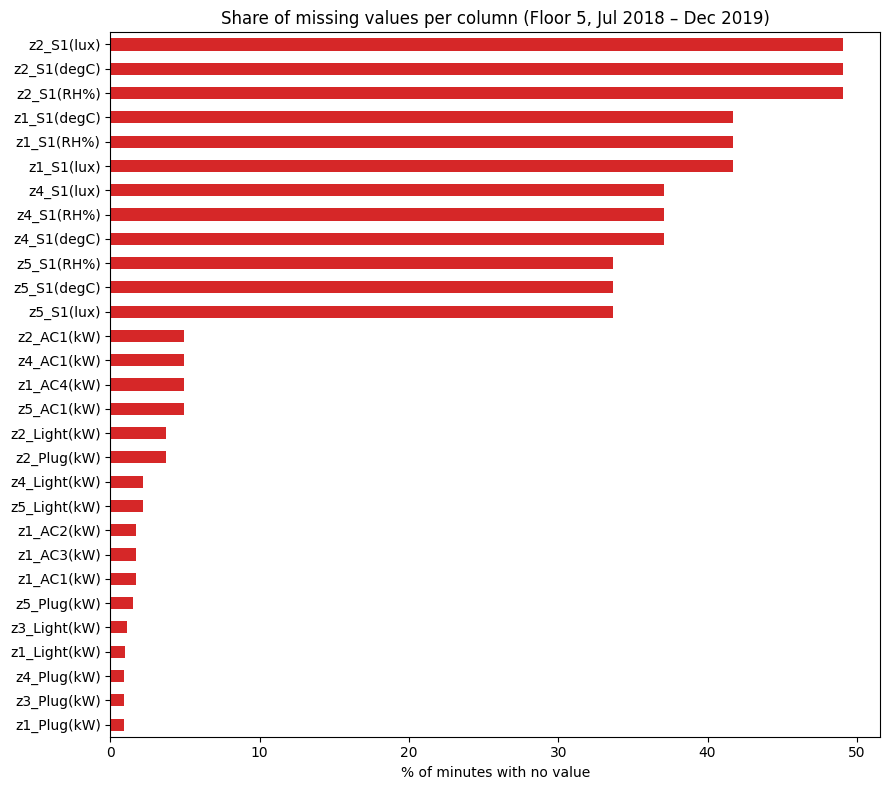

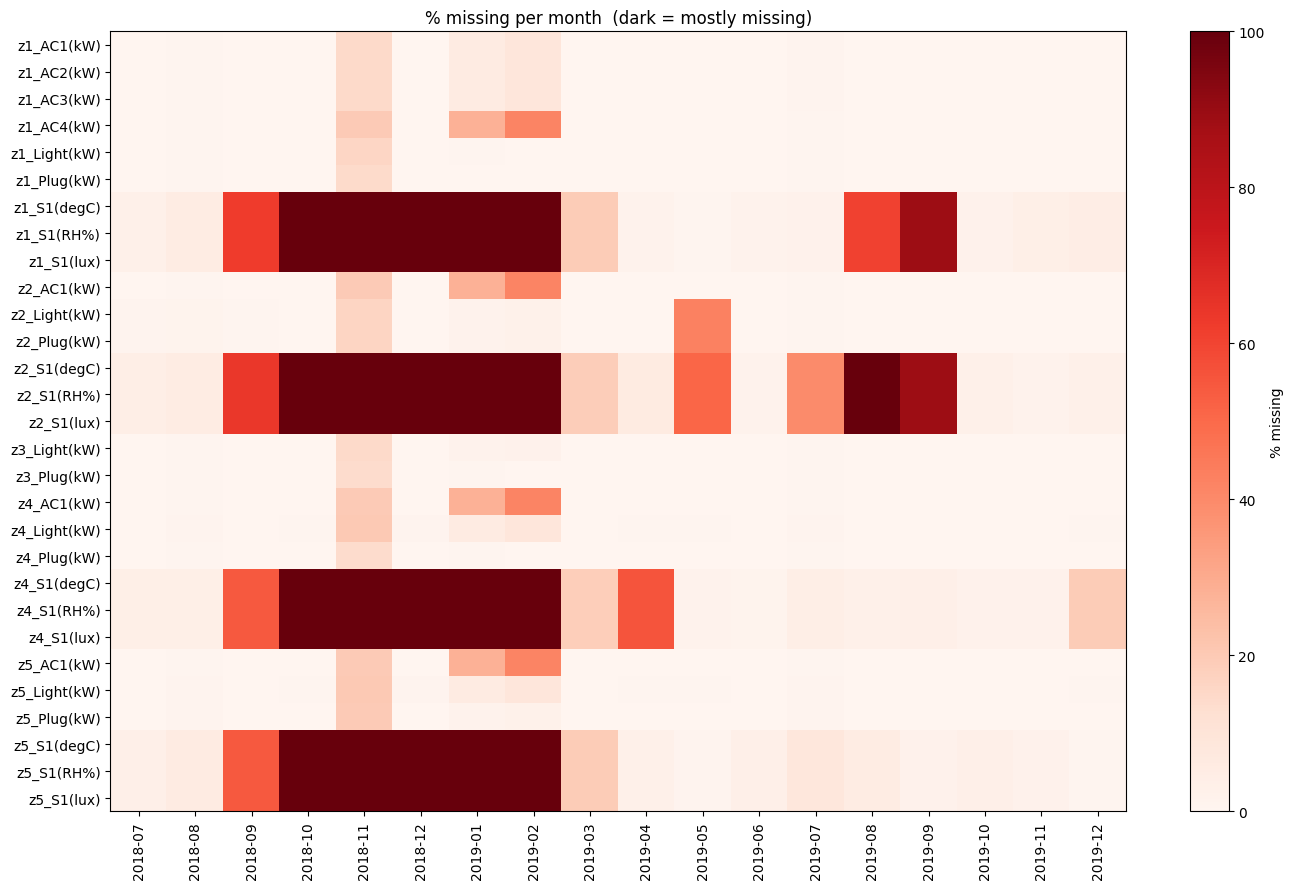

In [43]:
missing_pct = df.isna().mean().mul(100).round(1).sort_values(ascending=False)

ax = missing_pct.plot.barh(figsize=(9, 8), color="tab:red")
ax.set_xlabel("% of minutes with no value")
ax.set_title("Share of missing values per column (Floor 5, Jul 2018 – Dec 2019)")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

# Percentage of missing minutes per column per month
monthly_missing = df.isna().resample("MS").mean().mul(100)
monthly_missing.index = monthly_missing.index.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(14, 9))
im = ax.imshow(monthly_missing.T, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(len(monthly_missing.index)), monthly_missing.index, rotation=90)
ax.set_yticks(range(len(monthly_missing.columns)), monthly_missing.columns)
ax.set_title("% missing per month  (dark = mostly missing)")
plt.colorbar(im, ax=ax, label="% missing")
plt.tight_layout(); plt.show()

**Findings**

- **Power meters** (AC, Light, Plug) are mostly complete: a few percent missing, worst in Nov 2018
  and for `z1_AC4` in Jan–Feb 2019.
- **All indoor sensors are completely missing from roughly 15 Sep 2018 to 5 Mar 2019** (172 days). That is a
  nearly six-month blackout, not random loss. Temperature/comfort analysis can only use
  *Jul – mid Sep 2018* and *Mar–Dec 2019*.
- The **z1 sensor** also drops out for most of Aug–Sep 2019.

First day with NO temperature at all : 2018-09-15
Last day with NO temperature at all  : 2019-03-05
Number of days with zero temperature : 172


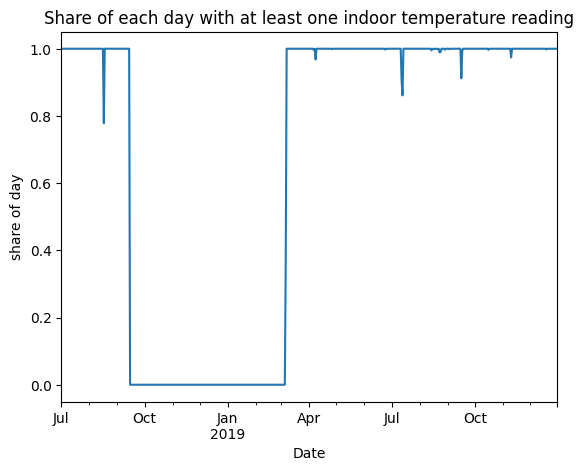

In [44]:
temp_present = df[TEMP_COLS].notna().any(axis=1)        # True when at least one zone reports temperature
daily_present = temp_present.resample("D").mean()          # share of each day with a temperature reading

gap_days = daily_present[daily_present == 0]
print("First day with NO temperature at all :", gap_days.index.min().date())
print("Last day with NO temperature at all  :", gap_days.index.max().date())
print("Number of days with zero temperature :", len(gap_days))

ax = daily_present.plot(title="Share of each day with at least one indoor temperature reading")
ax.set_ylabel("share of day"); plt.show()

## Looking for impossible values

Summary statistic per column to find maxima that does not make sense. 

In [47]:
summary = df.describe().T[["count", "mean", "min", "50%", "max"]].round(2)
summary["count"] = summary["count"].astype(int)
summary

,count,mean,min,50%,max
z1_AC1(kW),776956,0.00,0.00,0.00,1.22
z1_AC2(kW),776956,0.01,0.00,0.00,1.95
z1_AC3(kW),776956,0.01,0.00,0.00,3.20
z1_AC4(kW),751439,5.23,0.00,0.00,59.44
z1_Light(kW),782481,1.68,0.00,0.00,76.78
z1_Plug(kW),783319,0.54,0.00,0.25,97.08
z1_S1(degC),461038,23.68,10.83,24.92,30.90
z1_S1(RH%),461038,68.95,46.55,68.67,91.74
z1_S1(lux),461038,17.46,0.00,0.00,68.00
z2_AC1(kW),751517,3.52,0.00,0.00,58.17


In [48]:
# Compare the maximum in each year side by side – glitches usually show up in only one year
max_by_year = df.groupby(df.index.year)[POWER_COLS].max().T.round(1)
max_by_year.columns = [f"max {c}" for c in max_by_year.columns]
max_by_year["ratio 2018/2019"] = (max_by_year.iloc[:, 0] / max_by_year.iloc[:, 1]).round(1)
max_by_year.sort_values("ratio 2018/2019", ascending=False)

,max 2018,max 2019,ratio 2018/2019
z1_Plug(kW),97.1,5.6,17.3
z1_Light(kW),76.8,15.8,4.9
z2_Light(kW),56.0,14.3,3.9
z2_Plug(kW),5.4,1.9,2.8
z4_Plug(kW),16.3,12.6,1.3
z5_Light(kW),22.6,21.1,1.1
z4_Light(kW),27.9,26.6,1.0
z3_Plug(kW),0.8,0.8,1.0
z1_AC1(kW),1.2,1.2,1.0
z1_AC2(kW),1.9,2.0,1.0


**Findings**

- `z1_Plug(kW)`, `z1_Light(kW)` and `z2_Light(kW)` have 2018 maxima **4–17× larger** than anything seen in 2019. Those are meter glitches, not real loads. Will need to see how much it has impacted. 
- `z1_AC1(kW)` has a mean of ~0: this unit is effectively **never on**. => Dead
- `z1_AC2` and `z1_AC3` peak at only 2–3 kW, while `z1_AC4` peaks near 59 kW like the other zones' units.
  In practice **z1's cooling is `z1_AC4`**; the other three are small or idle.
- Temperature min of ~11 °C is weird for a Bangkok office; likely a defect

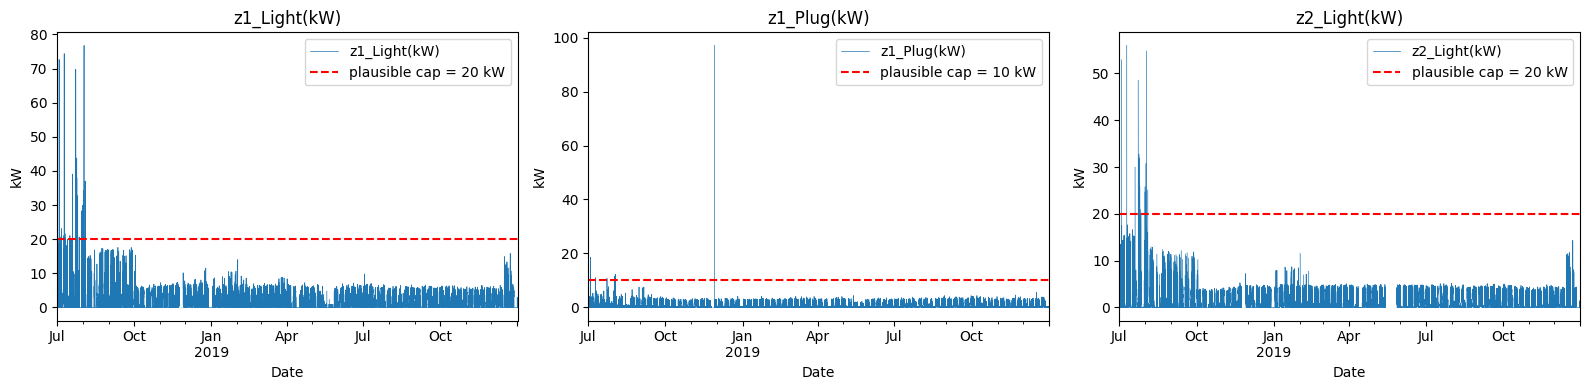

z1_Light(kW): 38 minutes above 20 kW  (0.005% of readings)
z1_Plug(kW): 6 minutes above 10 kW  (0.001% of readings)
z2_Light(kW): 16 minutes above 20 kW  (0.002% of readings)


In [49]:
GLITCH_CAPS = {"z1_Light(kW)": 20, "z1_Plug(kW)": 10, "z2_Light(kW)": 20}   # kW, above = impossible

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, cap) in zip(axes, GLITCH_CAPS.items()):
    df[col].plot(ax=ax, lw=0.5, title=col)
    ax.axhline(cap, color="red", ls="--", label=f"plausible cap = {cap} kW")
    ax.set_ylabel("kW"); ax.legend()
plt.tight_layout(); plt.show()

for col, cap in GLITCH_CAPS.items():
    n = (df[col] > cap).sum()
    print(f"{col}: {n} minutes above {cap} kW  ({n / df[col].notna().sum() * 100:.3f}% of readings)")

The spikes are a handful of isolated minutes. Changed to NaN

In [50]:
clean = df.copy()
for col, cap in GLITCH_CAPS.items():
    clean.loc[clean[col] > cap, col] = np.nan
print("Max after cleaning:", clean[list(GLITCH_CAPS)].max().round(2).to_dict())

Max after cleaning: {'z1_Light(kW)': 19.98, 'z1_Plug(kW)': 8.28, 'z2_Light(kW)': 18.81}


## Floor 5 energy usage

The meters report **power in kW every minute**. Energy in kWh for one minute is `kW × (1/60) h`.
Summing those gives kWh per day. We total by end-use (AC / Light / Plug) and by zone.

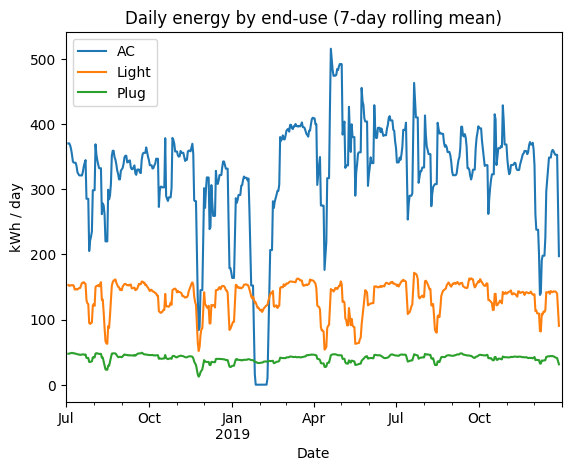

Share of total energy: {'AC': 64.8, 'Light': 27.0, 'Plug': 8.2}


In [51]:
kwh_min = clean[POWER_COLS] / 60           # energy per minute, kWh
daily_kwh = kwh_min.resample("D").sum(min_count=1)   # NaN if the whole day is empty

daily_by_use = pd.DataFrame({
    "AC":    daily_kwh[AC_COLS].sum(axis=1),
    "Light": daily_kwh[LIGHT_COLS].sum(axis=1),
    "Plug":  daily_kwh[PLUG_COLS].sum(axis=1),
})

ax = daily_by_use.rolling(7, center=True).mean().plot(title="Daily energy by end-use (7-day rolling mean)")
ax.set_ylabel("kWh / day"); plt.show()

share = daily_by_use.sum() / daily_by_use.sum().sum() * 100
print("Share of total energy:", share.round(1).to_dict())

In [53]:
# Energy per zone, per end-use, over the whole period
zone_use = (daily_kwh.sum()
            .rename_axis("column").reset_index(name="kWh")
            .merge(measurements[["column", "zone", "kind"]], on="column")
            .pivot_table(index="zone", columns="kind", values="kWh", aggfunc="sum", fill_value=0)
            .round(0))
zone_use["Total"] = zone_use.sum(axis=1)
zone_use.astype(int)

kind,AC,Light,Plug,Total
zone,,,,
z1,65750,21947,7043,94740
z2,44089,15543,1384,61016
z3,0,4551,3546,8097
z4,46240,18709,8891,73840
z5,21835,13357,1524,36716


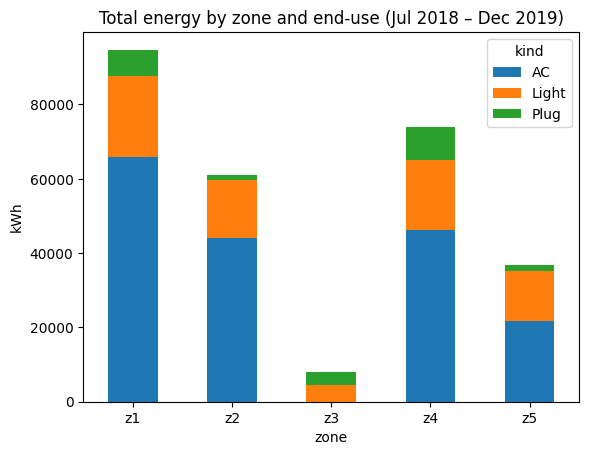

In [54]:
ax = zone_use.drop(columns="Total").plot.bar(stacked=True, title="Total energy by zone and end-use (Jul 2018 – Dec 2019)")
ax.set_ylabel("kWh"); ax.set_xlabel("zone"); plt.xticks(rotation=0); plt.show()

**Findings**

- Air-conditioning dominates. 
- Zones are not equal: z1 uses ~95 MWh over the period, z4 ~74 MWh, z2 ~61 MWh, z5 ~37 MWh, z3 only ~8 MWh. 
- Daily totals show a clear weekly rhythm (dips at weekends) and some seasonality.

## What does a typical day look like?

Averaging power by hour of day tells us **when** the building is in use, and whether equipment keeps
running when it should not. We separate weekdays from weekends.

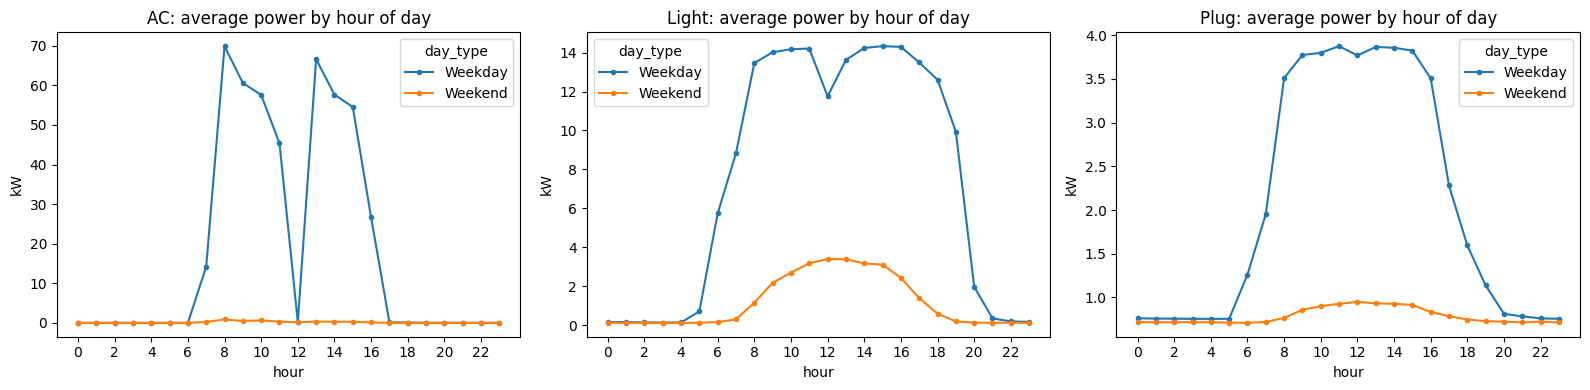

In [56]:
hourly = clean[POWER_COLS].resample("h").mean()
profile = pd.DataFrame({
    "AC":    hourly[AC_COLS].sum(axis=1),
    "Light": hourly[LIGHT_COLS].sum(axis=1),
    "Plug":  hourly[PLUG_COLS].sum(axis=1),
})
profile["hour"] = profile.index.hour
profile["day_type"] = np.where(profile.index.dayofweek < 5, "Weekday", "Weekend")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, use in zip(axes, ["AC", "Light", "Plug"]):
    profile.pivot_table(index="hour", columns="day_type", values=use, aggfunc="mean").plot(ax=ax, marker="o", ms=3)
    ax.set_title(f"{use}: average power by hour of day"); ax.set_ylabel("kW"); ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

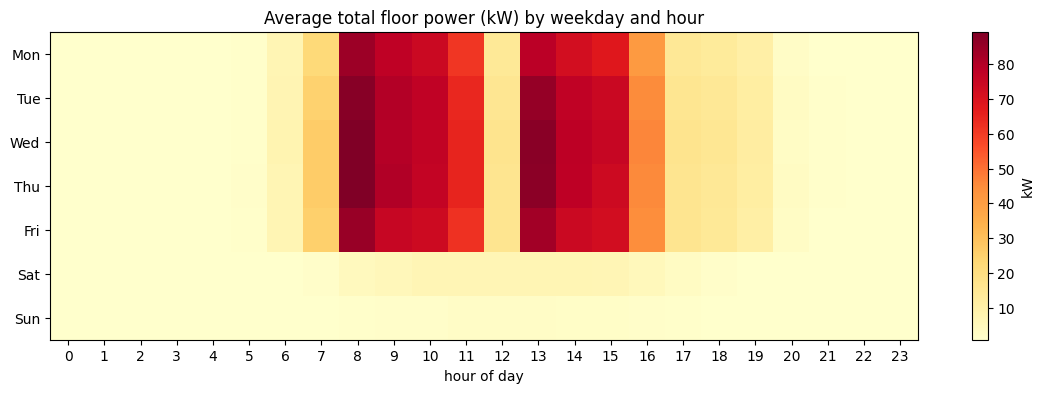

In [57]:
total_kw = hourly[POWER_COLS].sum(axis=1).to_frame("kW")
total_kw["hour"] = total_kw.index.hour
total_kw["dow"] = total_kw.index.dayofweek
heat = total_kw.pivot_table(index="dow", columns="hour", values="kW", aggfunc="mean")
heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(heat, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(24)); ax.set_yticks(range(7), heat.index)
ax.set_xlabel("hour of day"); ax.set_title("Average total floor power (kW) by weekday and hour")
plt.colorbar(im, ax=ax, label="kW"); plt.show()

**Findings**

- The floor "wakes up" around **07:00–08:00** and winds down around **18:00–19:00** on weekdays.
- Weekend AC and lighting are much lower but **not zero** 
- Plug load has a **flat overnight baseline** that never switches off (equipment left on standby).

## Indoor conditions

Only the months where sensors were alive count here (see section 5). We look at temperature
distributions per zone, and how temperature moves across a typical weekday.

Minutes with at least one temperature reading: 541,041 of 790,560


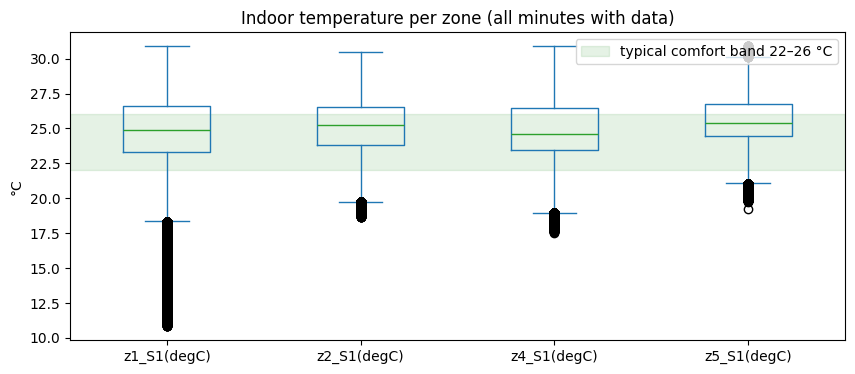

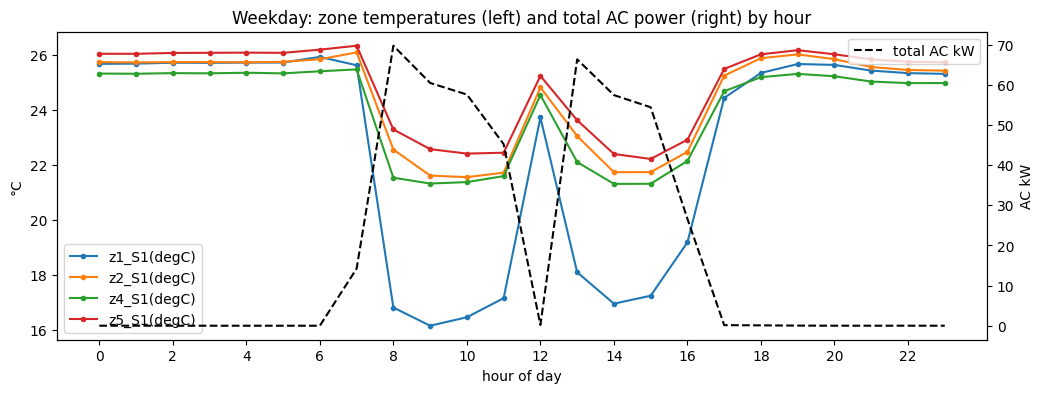

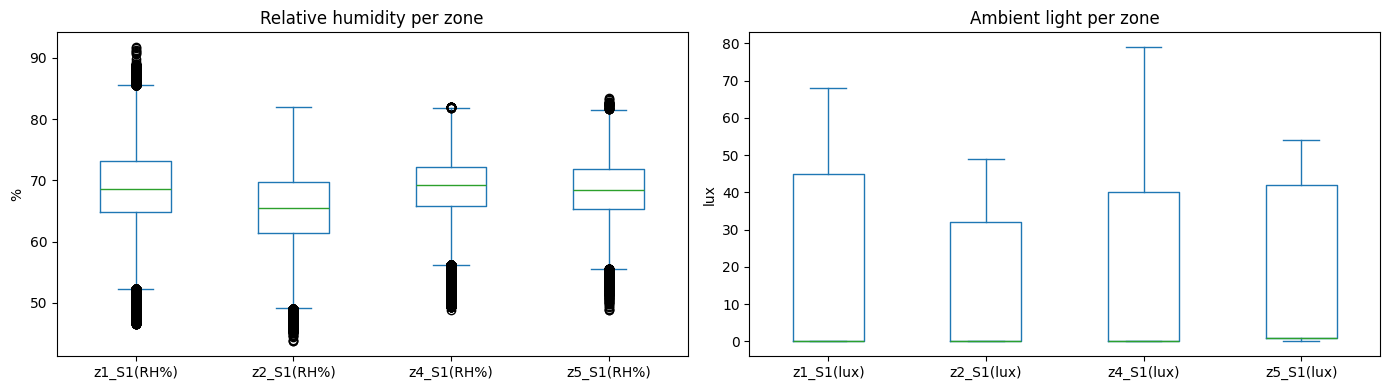

Max lux ever recorded: 79.0


In [62]:
temps = clean[TEMP_COLS].dropna(how="all")
print(f"Minutes with at least one temperature reading: {len(temps):,} of {len(clean):,}")

ax = temps.plot.box(figsize=(10, 4), title="Indoor temperature per zone (all minutes with data)")
ax.axhspan(22, 26, color="green", alpha=0.1, label="typical comfort band 22–26 °C")
ax.set_ylabel("°C"); ax.legend(loc="upper right"); plt.show()

# Typical weekday temperature and AC power, hour by hour
wk = clean[clean.index.dayofweek < 5]
hourly_temp = wk[TEMP_COLS].groupby(wk.index.hour).mean()
hourly_ac   = wk[AC_COLS].sum(axis=1).groupby(wk.index.hour).mean()

fig, ax1 = plt.subplots(figsize=(12, 4))
hourly_temp.plot(ax=ax1, marker="o", ms=3)
ax1.set_ylabel("°C"); ax1.set_xlabel("hour of day"); ax1.set_xticks(range(0, 24, 2))
ax2 = ax1.twinx()
hourly_ac.plot(ax=ax2, color="black", ls="--", label="total AC kW")
ax2.set_ylabel("AC kW"); ax2.legend(loc="upper right")
ax1.set_title("Weekday: zone temperatures (left) and total AC power (right) by hour")
plt.show()

# Humidity and light, briefly
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
clean[RELATIVE_HUMIDITY_COLS].plot.box(ax=axes[0], title="Relative humidity per zone"); axes[0].set_ylabel("%")
clean[ILLUMINANCE].plot.box(ax=axes[1], title="Ambient light per zone"); axes[1].set_ylabel("lux")
plt.tight_layout(); plt.show()
print("Max lux ever recorded:", clean[ILLUMINANCE].max().max())

**Findings**

- Occupied-hours temperatures sit mostly in the low-to-mid 20s °C; some zones spend time
  **below 22 °C**, which might be over-cooling. 
- Temperature rises overnight when AC is off and falls quickly once AC starts in the morning.
- Humidity is high (Bangkok) but AC keeps it in a reasonable band during the day.
- **Lux never exceeds ~80.** A lit office is typically 300–500 lux, so this channel is either mis-scaled
  or the sensor is badly placed. Use lux only as a *relative* signal, never as absolute illuminance.

## Summary 

| Topic | Finding | Consequence for the project |
|---|---|---|
| Time axis | Perfect 1-minute grid, 790,560 rows, no gaps | Missing data = empty cells, never missing rows |
| Zones | z1 has 4 AC units; z3 has no AC and no sensor | Comfort/AC work covers z1, z2, z4, z5 only |
| Missing power | A few % missing, worst Nov 2018 and `z1_AC4` Jan–Feb 2019 | Use `min_count` when summing; document coverage |
| Missing sensors | All temp/RH/lux missing 15 Sep 2018 → 5 Mar 2019 (172 days) | Comfort analysis limited to Jul–mid Sep 2018 and Mar–Dec 2019 |
| Glitches | ~50 spike minutes in `z1_Light`/`z1_Plug`/`z2_Light` (2018); `z1_AC1` idle, `z1_AC2/3` tiny | Cap and flag; compare `z1_AC4`, `z2_AC1`, `z4_AC1`, `z5_AC1` as peers |
| Energy mix | AC 65 %, Light 27 %, Plug 8 %; z1 is the largest zone | Biggest savings potential is in AC scheduling |
| Schedule | Occupied ~07:00–19:00 weekdays; non-zero weekend and overnight load | Basis for the after-hours question |
| Comfort | Some zones below 22 °C in occupied hours | Basis for the over-cooling question |
| Lux | Max ~80 lux, mis-scaled | Relative use only |